# SKAB 지도·비지도 이상탐지 비교

**실행 순서:** 아래 셀을 위에서부터 실행합니다. CPU만으로 실행할 수 있습니다. 전체 설명과 이번 실측 결과는 마지막 Markdown 셀에 있습니다. 원본 노트북은 수정하지 않은 별도 완성본입니다.

모델: RF·HGB(지도), IF(정상 전용 학습). 개선 IF의 검증에는 라벨을 사용합니다. 데이터 누수 방지, Point Adjustment 미적용, 3회 파일 분할 반복을 적용합니다.

In [1]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'numpy', 'pandas', 'matplotlib', 'scikit-learn>=1.3,<2', 'joblib'])
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
BASE_DIR = Path('/content/drive/MyDrive/CBNU/어프렌티스 프로젝트/SKAB_Project')
for folder in ['img', 'results', 'models']:
    (BASE_DIR / folder).mkdir(parents=True, exist_ok=True)
print('모든 시각화 저장:', BASE_DIR / 'img')

Mounted at /content/drive
모든 시각화 저장: /content/drive/MyDrive/CBNU/어프렌티스 프로젝트/SKAB_Project/img


In [2]:
"""SKAB reproducible experiment. Python 3.10+, scikit-learn >=1.3.
Run: python skab_pipeline.py --base ./SKAB_Project --repo ./skab_source
Colab: see SKAB_experiment.ipynb. No point adjustment; larger score=anomaly.
"""
from pathlib import Path
import argparse, hashlib, json, platform, subprocess, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, precision_recall_curve, roc_curve, auc, confusion_matrix)
from sklearn.utils.class_weight import compute_sample_weight

SENSORS = ['Accelerometer1RMS','Accelerometer2RMS','Current','Pressure',
           'Temperature','Thermocouple','Voltage','Volume Flow RateRMS']
METRICS = ['Precision','Recall','F1','ROC_AUC','PR_AUC','AP']
MAX_WINDOW = 30

def markdown_table(frame, index=True, digits=4):
    d=frame.reset_index() if index else frame.copy()
    def fmt(v):
        return f'{v:.{digits}f}' if isinstance(v,(float,np.floating)) else str(v)
    rows=['| '+' | '.join(map(str,d.columns))+' |', '| '+' | '.join(['---']*len(d.columns))+' |']
    rows += ['| '+' | '.join(fmt(v) for v in row)+' |' for row in d.itertuples(index=False,name=None)]
    return '\n'.join(rows)



## 1. Directories, acquisition and quality checks

CSV 구조와 시간 품질을 검증합니다. 기존 폴더를 삭제하지 않습니다.

In [3]:

def directories(base):
    base = Path(base)
    paths = {k: base / k for k in ['img','results','models']}
    for p in paths.values(): p.mkdir(parents=True, exist_ok=True)
    return paths

def acquire(repo):
    repo = Path(repo)
    if not (repo / 'data').exists():
        if repo.exists(): raise FileExistsError(f'Existing directory is not a SKAB repo: {repo}')
        subprocess.run(['git','clone','--depth','1','https://github.com/waico/SKAB.git',str(repo)], check=True)
    return repo

def load_data(repo):
    data, quality, hashes = {}, [], {}
    for p in sorted((Path(repo)/'data').rglob('*.csv')):
        name = p.relative_to(Path(repo)/'data').as_posix()
        # Only the benchmark corpus, excluding future auxiliary CSVs.
        if name.split('/')[0] not in ['anomaly-free','valve1','valve2','other']: continue
        d = pd.read_csv(p, sep=';'); d.columns = d.columns.str.strip()
        missing = set(SENSORS + ['datetime']) - set(d)
        if missing: raise ValueError(f'{name}: missing {missing}')
        dt = pd.to_datetime(d.datetime, errors='coerce')
        if dt.isna().any() or dt.duplicated().any() or not dt.is_monotonic_increasing:
            raise ValueError(f'{name}: invalid/duplicate/unsorted time; inspect before proceeding')
        d['datetime'] = dt
        d[SENSORS] = d[SENSORS].apply(pd.to_numeric, errors='coerce').replace([np.inf,-np.inf],np.nan)
        if name.startswith('anomaly-free/'):
            d['anomaly'] = 0  # official normal recording, not a target for supervised anomaly examples
        elif 'anomaly' not in d: raise ValueError(f'{name}: missing anomaly label')
        if not d.anomaly.isin([0,1]).all(): raise ValueError(f'{name}: invalid labels')
        d['anomaly'] = d.anomaly.astype(int)
        # Gaps >3 nominal intervals reset windows and fill state; 1–2 s jitter is retained.
        dif = dt.diff().dt.total_seconds(); nominal = dif[dif>0].median()
        d['segment'] = (dif > 3*nominal).cumsum().astype(int)
        quality.append(dict(file=name, rows=len(d), missing=int(d[SENSORS].isna().sum().sum()),
                            anomaly_count=int(d.anomaly.sum()), anomaly_ratio=float(d.anomaly.mean()),
                            median_interval_seconds=float(nominal), gaps=int(d.segment.max()), irregular_intervals=int((dif.dropna()!=nominal).sum())))
        data[name] = d
        hashes[name] = hashlib.sha256(p.read_bytes()).hexdigest()
    if 'anomaly-free/anomaly-free.csv' not in data: raise ValueError('Normal recording missing')
    return data, pd.DataFrame(quality), hashes



## 2. File-disjoint split; normal recording separately split in time

파일 단위로 먼저 분리한 뒤 특징을 만듭니다. 정상 파일은 독립적인 시간 구간으로 나눕니다.

In [4]:

def split_data(data, seed):
    rng = np.random.default_rng(seed)
    splits = {'train':{},'val':{},'test':{}}
    manifest = []
    for category in ['valve1','valve2','other']:
        keys = sorted(k for k in data if k.startswith(category+'/'))
        if len(keys)<3: raise ValueError(f'{category}: need >=3 independent files')
        keys = list(rng.permutation(keys))
        nv = max(1, round(.2*len(keys))); nt = max(1, round(.2*len(keys)))
        ntr = len(keys)-nv-nt
        if ntr < 1: raise ValueError('Too few files')
        for part, kk in zip(splits, [keys[:ntr],keys[ntr:ntr+nv],keys[ntr+nv:]]):
            for k in kk:
                splits[part][k] = data[k].copy()
                manifest.append(dict(seed=seed, file=k, split=part, rows=len(data[k])))
    normal = data['anomaly-free/anomaly-free.csv']; a,b=int(.6*len(normal)),int(.8*len(normal))
    normal_splits = {}
    for part, d in zip(['train','cal','holdout'],[normal.iloc[:a],normal.iloc[a:b],normal.iloc[b:]]):
        normal_splits[part] = {f'anomaly-free/{part}':d.reset_index(drop=True).copy()}
        manifest.append(dict(seed=seed,file=f'anomaly-free/{part}',split=part,rows=len(d)))
    # Ensure file-level split is disjoint before creating overlapping windows.
    assert not (set(splits['train']) & set(splits['val']) or set(splits['train']) & set(splits['test']) or set(splits['val']) & set(splits['test']))
    return splits, normal_splits, pd.DataFrame(manifest)



## 3. Causal imputation, train-only scaling, common evaluation endpoints

과거값으로만 결측치를 채우고 학습 자료에서만 scaler를 fit합니다. y는 마지막 시점 라벨입니다.

In [5]:

def medians(records):
    m = pd.concat([d[SENSORS] for d in records.values()]).median()
    if m.isna().any(): raise ValueError('All-missing training sensor')
    return m

def features(records, med, mode='last', window=30):
    """Predict y[t] using x[t-window+1:t+1]; never include labels as features.
    All variants start at offset 29 within each segment for fair sample matching.
    Forward fill uses only past values, then train median for leading missingness.
    """
    xs, ys, meta = [], [], []
    for name,d in records.items():
        for _,seg in d.groupby('segment', sort=False):
            seg=seg.reset_index(drop=True)
            if len(seg)<MAX_WINDOW: continue
            x=seg[SENSORS].ffill().fillna(med)
            if mode=='last': z=x.to_numpy()
            else:
                roll=x.rolling(window, min_periods=window)
                z=np.concatenate([x.to_numpy(),roll.mean().to_numpy(),roll.std(ddof=0).to_numpy(),
                    roll.min().to_numpy(),roll.max().to_numpy(),
                    (x-x.shift(window-1)).to_numpy()],axis=1)
            sl=slice(MAX_WINDOW-1,None)
            xs.append(z[sl]); ys.append(seg.anomaly.to_numpy()[sl])
            meta.append(pd.DataFrame({'file':name,'datetime':seg.datetime.iloc[sl].to_numpy(),
                                      'segment':seg.segment.iloc[sl].to_numpy()}))
    if not xs: raise ValueError('No eligible windows')
    X=np.concatenate(xs).astype(np.float32); y=np.concatenate(ys)
    assert np.isfinite(X).all()
    return X,y,pd.concat(meta,ignore_index=True)

def metrics(y,s,t):
    pred=np.asarray(s)>=t
    p,r,_=precision_recall_curve(y,s)
    two=len(np.unique(y))==2
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(Precision=precision_score(y,pred,zero_division=0),
                Recall=recall_score(y,pred,zero_division=0),F1=f1_score(y,pred,zero_division=0),
                ROC_AUC=roc_auc_score(y,s) if two else np.nan,
                PR_AUC=auc(r,p) if two else np.nan, AP=average_precision_score(y,s) if two else np.nan,
                FPR=fp/(fp+tn) if fp+tn else np.nan,TP=int(tp),FP=int(fp),FN=int(fn),TN=int(tn))

def optimize_threshold(y,s):
    if len(np.unique(y))!=2: raise ValueError('Validation needs both classes')
    p,r,t=precision_recall_curve(y,s)
    f=2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1],1e-12)
    # Deterministic tie break: highest threshold among max-F1 candidates.
    j=np.flatnonzero(np.isclose(f,f.max(),rtol=0,atol=1e-12))[-1]
    return float(t[j])

def score(model,X,kind):
    return -model.score_samples(X) if kind=='IF' else model.predict_proba(X)[:,1]

def estimator(kind, seed, tuned=False):
    if kind=='RF':
        return RandomForestClassifier(n_estimators=160, max_depth=12 if tuned else None,
            min_samples_leaf=5 if tuned else 1,class_weight='balanced',n_jobs=-1,random_state=seed)
    if kind=='HGB':
        return HistGradientBoostingClassifier(max_iter=120,learning_rate=.05 if tuned else .1,
            max_leaf_nodes=15 if tuned else 31,l2_regularization=1 if tuned else 0,
            early_stopping=False,random_state=seed)
    return IsolationForest(n_estimators=160,max_samples=512 if tuned else 256,
        max_features=.75 if tuned else 1.,contamination='auto',n_jobs=-1,random_state=seed)



## 4. Fit candidates, tune on validation only, then unlock test

후보와 임계값 선택은 validation만 사용합니다. 모델별 학습과 추론 함수가 포함되어 있습니다.

In [6]:

def run_seed(data, seed, paths):
    splits, normal, manifest=split_data(data,seed)
    manifest.to_csv(paths['results']/f'split_{seed}.csv',index=False)
    candidates=[]; selected=[]; histories=[]
    for kind in ['RF','HGB','IF']:
        # IF never sees anomaly labels at fit, nor label-selected normal rows.
        train = normal['train'] if kind=='IF' else {**splits['train'],**normal['train']}
        med=medians(train)
        settings=[('last',30,False),('rolling',30,False),('rolling',10,False),
                  ('rolling',30,True),('rolling',10,True)]
        fitted=[]
        for mode,w,tuned in settings:
            X,y,_=features(train,med,mode,w)
            scaler=StandardScaler().fit(X); X=scaler.transform(X)
            model=estimator(kind,seed,tuned)
            begin=time.perf_counter()
            if kind=='IF': model.fit(X)
            elif kind=='HGB': model.fit(X,y,sample_weight=compute_sample_weight('balanced',y))
            else: model.fit(X,y)
            elapsed=time.perf_counter()-begin
            vx,vy,_=features(splits['val'],med,mode,w)
            vs=score(model,scaler.transform(vx),kind)
            threshold=optimize_threshold(vy,vs)
            if kind=='IF':
                cx,_,_=features(normal['cal'],med,mode,w)
                base_t=float(np.quantile(score(model,scaler.transform(cx),kind),.99))
            else: base_t=.5
            rec=dict(seed=seed,model=kind,mode=mode,window=w,tuned=tuned,
                     threshold=threshold,baseline_threshold=base_t,train_seconds=elapsed,
                     **{'val_'+k:v for k,v in metrics(vy,vs,threshold).items()})
            histories.append(rec)
            fitted.append(dict(record=rec,model=model,scaler=scaler,medians=med,kind=kind,
                               mode=mode,window=w,validation_y=vy,validation_score=vs))
        # Lock selected parameters using validation AP (no test access yet).
        best=max(fitted[1:],key=lambda a:a['record']['val_AP'])
        stages=[('baseline',fitted[0],fitted[0]['record']['baseline_threshold']),
                ('threshold',fitted[0],fitted[0]['record']['threshold']),
                ('features',fitted[1],fitted[1]['record']['threshold']),
                ('tuned',best,best['record']['threshold'])]
        for stage,bundle,threshold in stages:
            rec=bundle['record']; tx,ty,tm=features(splits['test'],med,bundle['mode'],bundle['window'])
            begin=time.perf_counter()
            ts=score(bundle['model'],bundle['scaler'].transform(tx),kind)
            infer_ms=1000*(time.perf_counter()-begin)/len(tx)
            row=dict(seed=seed,model=kind,stage=stage,threshold=threshold,
                     mode=bundle['mode'],window=bundle['window'],tuned=rec['tuned'],
                     train_seconds=rec['train_seconds'],inference_ms_per_point=infer_ms,
                     val_AP=rec['val_AP'],**metrics(ty,ts,threshold))
            candidates.append(row)
            pred=tm.assign(y=ty,score=ts,pred=(ts>=threshold).astype(int))
            pred.to_csv(paths['results']/f'predictions_{seed}_{kind}_{stage}.csv',index=False)
            if stage=='tuned':
                selected.append((kind,pred,threshold))
                saved={k:v for k,v in bundle.items() if not k.startswith('validation_')}
                saved.update(threshold=threshold,sensors=SENSORS,max_window=MAX_WINDOW)
                joblib.dump(saved,paths['models']/f'{kind}_{seed}.joblib')
                # Never-used normal holdout: operational false-alarm check.
                nx,_,nm=features(normal['holdout'],med,bundle['mode'],bundle['window'])
                ns=score(bundle['model'],bundle['scaler'].transform(nx),kind)
                row['normal_holdout_FPR']=float(np.mean(ns>=threshold))
                # Comparison without validation-label threshold for IF, on SAME selected scoring model.
                # Model selection still uses labels; this is NOT a fully unsupervised pipeline.
                row['normal_cal_threshold']=rec['baseline_threshold']
        print(f'Seed {seed}: {kind} complete',flush=True)
    pd.DataFrame(histories).to_csv(paths['results']/f'validation_history_{seed}.csv',index=False)
    plot_seed(candidates,selected,seed,paths)
    return candidates



## 5. Figures, file-level scores and event diagnostics (no point adjustment)

모든 그림을 img에 저장합니다. 예측을 보정하지 않은 point-wise 점수를 사용합니다.

In [7]:

def savefig(fig,paths,name):
    fig.tight_layout(); fig.savefig(paths['img']/name,dpi=170,bbox_inches='tight'); plt.close(fig)

def plot_seed(rows,selected,seed,paths):
    frame=pd.DataFrame(rows)
    fig,ax=plt.subplots(figsize=(9,4))
    frame.pivot(index='model',columns='stage',values='F1')[['baseline','threshold','features','tuned']].plot.bar(ax=ax)
    ax.set_ylim(0,1); ax.set_ylabel('Point-wise F1 (no adjustment)')
    savefig(fig,paths,f'ablation_{seed}.png')
    fig,axes=plt.subplots(1,2,figsize=(11,4)); files=[]; events=[]
    for kind,pred,t in selected:
        y,s=pred.y.to_numpy(),pred.score.to_numpy()
        pr,re,_=precision_recall_curve(y,s); fpr,tpr,_=roc_curve(y,s)
        axes[0].plot(re,pr,label=kind); axes[1].plot(fpr,tpr,label=kind)
        for name,g in pred.groupby('file',sort=True):
            files.append(dict(seed=seed,model=kind,file=name,**metrics(g.y,g.score,t)))
            # Contiguous anomaly events in each uninterrupted segment.
            for _,seg in g.groupby('segment',sort=False):
                yy=seg.y.to_numpy(); pp=seg.pred.to_numpy()
                edges=np.diff(np.r_[0,yy,0]); starts=np.where(edges==1)[0]; ends=np.where(edges==-1)[0]
                for a,b in zip(starts,ends):
                    hits=np.flatnonzero(pp[a:b]); hit=bool(len(hits))
                    delay=(pd.Timestamp(seg.datetime.iloc[a+hits[0]])-pd.Timestamp(seg.datetime.iloc[a])).total_seconds() if hit else np.nan
                    events.append(dict(seed=seed,model=kind,file=name,detected=int(hit),delay_seconds=delay))
        # Deterministic example, not chosen for good performance.
        name=sorted(pred.file.unique())[0]; g=pred[pred.file==name]
        fig,ax=plt.subplots(figsize=(11,3)); ax.plot(pd.to_datetime(g.datetime),g.score,label='Score',lw=.8)
        ax.axhline(t,color='red',ls='--',label='Threshold')
        ax.fill_between(pd.to_datetime(g.datetime),0,1,where=g.y==1,transform=ax.get_xaxis_transform(),alpha=.15,color='red',label='True anomaly')
        ax.set_title(f'{kind}: {name}'); ax.legend(); savefig(fig,paths,f'timeline_{seed}_{kind}.png')
        cm=confusion_matrix(y,pred.pred,labels=[0,1]); fig,ax=plt.subplots(figsize=(4,4))
        ax.imshow(cm,cmap='Blues'); ax.set(xticks=[0,1],yticks=[0,1],xlabel='Prediction',ylabel='True label',title=kind)
        for (i,j),v in np.ndenumerate(cm): ax.text(j,i,str(v),ha='center',va='center')
        savefig(fig,paths,f'confusion_{seed}_{kind}.png')
    axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision-recall'); axes[1].set(xlabel='FPR',ylabel='TPR',title='ROC')
    axes[0].axhline(float(selected[0][1].y.mean()),color='gray',ls='--',label='Prevalence')
    axes[1].plot([0,1],[0,1],'k--')
    for ax in axes: ax.legend(); ax.grid(alpha=.2)
    savefig(axes[0].figure,paths,f'curves_{seed}.png')
    pd.DataFrame(files).to_csv(paths['results']/f'per_file_{seed}.csv',index=False)
    pd.DataFrame(events).to_csv(paths['results']/f'events_{seed}.csv',index=False)

def predict_file(bundle_path,csv_path):
    """Batch inference for a new file, no labels required. First 29 points warm up.
    Only load trusted joblib files. Call features identically to training.
    """
    b=joblib.load(bundle_path); d=pd.read_csv(csv_path,sep=';'); d.columns=d.columns.str.strip()
    d['datetime']=pd.to_datetime(d.datetime,errors='raise')
    if d.datetime.duplicated().any() or not d.datetime.is_monotonic_increasing: raise ValueError('Invalid time order')
    d[SENSORS]=d[SENSORS].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
    delta=d.datetime.diff().dt.total_seconds(); nominal=delta[delta>0].median()
    d['segment']=(delta>3*nominal).cumsum(); d['anomaly']=0 # ignored at inference
    X,_,meta=features({Path(csv_path).name:d},b['medians'],b['mode'],b['window'])
    s=score(b['model'],b['scaler'].transform(X),b['kind'])
    return meta.assign(score=s,pred=(s>=b['threshold']).astype(int))



## 6. Reproducible main experiment

각 split seed에서 전체 실험을 반복하고 표와 개선량을 저장합니다.

In [8]:

def main(base,repo=None,seeds=(42,43,44)):
    paths=directories(base); repo=acquire(repo or Path(base)/'SKAB')
    data,quality,hashes=load_data(repo)
    quality.to_csv(paths['results']/'data_quality.csv',index=False)
    fig,ax=plt.subplots(figsize=(12,4)); quality.set_index('file').anomaly_ratio.plot.bar(ax=ax)
    ax.set_ylabel('Anomaly fraction'); savefig(fig,paths,'label_distribution.png')
    try: commit=subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'],text=True).strip()
    except subprocess.CalledProcessError: commit='unknown'
    metadata=dict(seeds=list(seeds),commit=commit,hashes=hashes,python=platform.python_version(),
        sklearn=sklearn.__version__,numpy=np.__version__,pandas=pd.__version__,max_window=MAX_WINDOW,
        protocol='category-stratified file-disjoint 60/20/20 approximately; no point adjustment',
        note='IF fit uses only official normal train; improved threshold and candidate selection use validation labels')
    (paths['results']/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
    rows=[]
    for seed in seeds: rows.extend(run_seed(data,seed,paths))
    out=pd.DataFrame(rows); out.to_csv(paths['results']/'all_results.csv',index=False)
    return summarize(out,paths)

def summarize(out,paths):
    final=out[out.stage=='tuned']; summary=final.groupby('model')[METRICS].agg(['mean','std'])
    summary.to_csv(paths['results']/'final_summary.csv')
    md='# SKAB measured results\n\nNo point adjustment. Mean ± sample SD across file-split seeds; SD is not a confidence interval.\n\n'
    table=pd.DataFrame({m:summary[m].apply(lambda x:f'{x["mean"]:.4f} ± {x["std"]:.4f}',axis=1) for m in METRICS})
    md+=markdown_table(table)+'\n\n## All predeclared stages\n\n'+markdown_table(out[['seed','model','stage']+METRICS],index=False)
    (paths['results']/'results.md').write_text(md,encoding='utf-8')
    fig,ax=plt.subplots(figsize=(10,4)); final.groupby('model')[METRICS].mean().plot.bar(ax=ax,ylim=(0,1))
    ax.set_ylabel('Mean score across splits'); ax.legend(loc='upper left',bbox_to_anchor=(1.01,1)); savefig(fig,paths,'final_comparison.png')
    # Paired deltas describe improvements; negative deltas must be retained.
    delta=out.pivot(index=['seed','model'],columns='stage',values='F1')
    delta['threshold_delta']=delta.threshold-delta.baseline
    delta['features_delta']=delta.features-delta.threshold
    delta['tuning_delta']=delta.tuned-delta.features
    delta.to_csv(paths['results']/'improvement_deltas.csv')
    print(markdown_table(table)); return out



Seed 42: RF complete
Seed 42: HGB complete
Seed 42: IF complete
Seed 43: RF complete
Seed 43: HGB complete
Seed 43: IF complete
Seed 44: RF complete
Seed 44: HGB complete
Seed 44: IF complete
| model | Precision | Recall | F1 | ROC_AUC | PR_AUC | AP |
| --- | --- | --- | --- | --- | --- | --- |
| HGB | 0.8006 ± 0.1197 | 0.6780 ± 0.1531 | 0.7208 ± 0.0726 | 0.8187 ± 0.0931 | 0.8104 ± 0.0789 | 0.8105 ± 0.0789 |
| IF | 0.3493 ± 0.0086 | 0.9421 ± 0.0916 | 0.5088 ± 0.0107 | 0.5539 ± 0.0443 | 0.4146 ± 0.0268 | 0.4149 ± 0.0267 |
| RF | 0.7967 ± 0.1516 | 0.6648 ± 0.1883 | 0.7009 ± 0.0768 | 0.8261 ± 0.1093 | 0.8111 ± 0.0859 | 0.8112 ± 0.0859 |


# SKAB measured results

No point adjustment. Mean ± sample SD across file-split seeds; SD is not a confidence interval.

| model | Precision | Recall | F1 | ROC_AUC | PR_AUC | AP |
| --- | --- | --- | --- | --- | --- | --- |
| HGB | 0.8006 ± 0.1197 | 0.6780 ± 0.1531 | 0.7208 ± 0.0726 | 0.8187 ± 0.0931 | 0.8104 ± 0.0789 | 0.8105 ± 0.0789 |
| IF | 0.3493 ± 0.0086 | 0.9421 ± 0.0916 | 0.5088 ± 0.0107 | 0.5539 ± 0.0443 | 0.4146 ± 0.0268 | 0.4149 ± 0.0267 |
| RF | 0.7967 ± 0.1516 | 0.6648 ± 0.1883 | 0.7009 ± 0.0768 | 0.8261 ± 0.1093 | 0.8111 ± 0.0859 | 0.8112 ± 0.0859 |

## All predeclared stages

| seed | model | stage | Precision | Recall | F1 | ROC_AUC | PR_AUC | AP |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 42 | RF | baseline | 0.7953 | 0.7304 | 0.7615 | 0.8836 | 0.8481 | 0.8458 |
| 42 | RF | threshold | 0.8548 | 0.6573 | 0.7432 | 0.8836 | 0.8481 | 0.8458 |
| 42 | RF | features | 0.5495 | 0.6922 | 0.6126 | 0.8372 | 0.7525 | 0.7450 |
| 42 | RF | tuned | 0.6896 | 0.6667 | 0.6780 | 0.8546 | 0.7802 | 0.7803 |
| 42 | HGB | baseline | 0.7506 | 0.7052 | 0.7272 | 0.8619 | 0.8216 | 0.8217 |
| 42 | HGB | threshold | 0.8493 | 0.6244 | 0.7197 | 0.8619 | 0.8216 | 0.8217 |
| 42 | HGB | features | 0.6191 | 0.6890 | 0.6522 | 0.8396 | 0.8037 | 0.8037 |
| 42 | HGB | tuned | 0.6978 | 0.6581 | 0.6774 | 0.8170 | 0.7732 | 0.7734 |
| 42 | IF | baseline | 0.3673 | 0.8116 | 0.5057 | 0.5158 | 0.3570 | 0.3573 |
| 42 | IF | threshold | 0.3552 | 0.9988 | 0.5240 | 0.5158 | 0.3570 | 0.3573 |
| 42 | IF | features | 0.3526 | 0.9842 | 0.5192 | 0.5601 | 0.4016 | 0.4020 |
| 42 | IF | tuned | 0.3528 | 0.9898 | 0.5202 | 0.5592 | 0.4119 | 0.4122 |
| 43 | RF | baseline | 0.9600 | 0.4692 | 0.6303 | 0.6992 | 0.7270 | 0.7253 |
| 43 | RF | threshold | 0.7994 | 0.5244 | 0.6334 | 0.6992 | 0.7270 | 0.7253 |
| 43 | RF | features | 0.9656 | 0.4008 | 0.5664 | 0.7258 | 0.7539 | 0.7524 |
| 43 | RF | tuned | 0.9701 | 0.4756 | 0.6382 | 0.7054 | 0.7449 | 0.7450 |
| 43 | HGB | baseline | 0.8570 | 0.5158 | 0.6440 | 0.6788 | 0.7216 | 0.7217 |
| 43 | HGB | threshold | 0.9761 | 0.4613 | 0.6265 | 0.6788 | 0.7216 | 0.7217 |
| 43 | HGB | features | 0.8723 | 0.5214 | 0.6527 | 0.7096 | 0.7350 | 0.7350 |
| 43 | HGB | tuned | 0.9320 | 0.5357 | 0.6804 | 0.7265 | 0.7570 | 0.7570 |
| 43 | IF | baseline | 0.3681 | 0.7195 | 0.4870 | 0.4961 | 0.3663 | 0.3666 |
| 43 | IF | threshold | 0.3635 | 0.8609 | 0.5112 | 0.4961 | 0.3663 | 0.3666 |
| 43 | IF | features | 0.3648 | 0.8135 | 0.5037 | 0.5145 | 0.3983 | 0.3985 |
| 43 | IF | tuned | 0.3556 | 0.8365 | 0.4990 | 0.5072 | 0.3893 | 0.3896 |
| 44 | RF | baseline | 0.7796 | 0.6280 | 0.6956 | 0.8444 | 0.8063 | 0.8043 |
| 44 | RF | threshold | 0.5885 | 0.7052 | 0.6416 | 0.8444 | 0.8063 | 0.8043 |
| 44 | RF | features | 0.6912 | 0.8530 | 0.7636 | 0.9180 | 0.9065 | 0.9051 |
| 44 | RF | tuned | 0.7303 | 0.8522 | 0.7865 | 0.9183 | 0.9082 | 0.9082 |
| 44 | HGB | baseline | 0.6915 | 0.6256 | 0.6569 | 0.8023 | 0.7809 | 0.7810 |
| 44 | HGB | threshold | 0.7075 | 0.6182 | 0.6598 | 0.8023 | 0.7809 | 0.7810 |
| 44 | HGB | features | 0.7720 | 0.8401 | 0.8046 | 0.9127 | 0.9011 | 0.9011 |
| 44 | HGB | tuned | 0.7720 | 0.8401 | 0.8046 | 0.9127 | 0.9011 | 0.9011 |
| 44 | IF | baseline | 0.3602 | 0.8577 | 0.5074 | 0.5328 | 0.3528 | 0.3531 |
| 44 | IF | threshold | 0.3396 | 1.0000 | 0.5070 | 0.5328 | 0.3528 | 0.3531 |
| 44 | IF | features | 0.3396 | 1.0000 | 0.5070 | 0.5953 | 0.4426 | 0.4428 |
| 44 | IF | tuned | 0.3396 | 1.0000 | 0.5070 | 0.5953 | 0.4426 | 0.4428 |

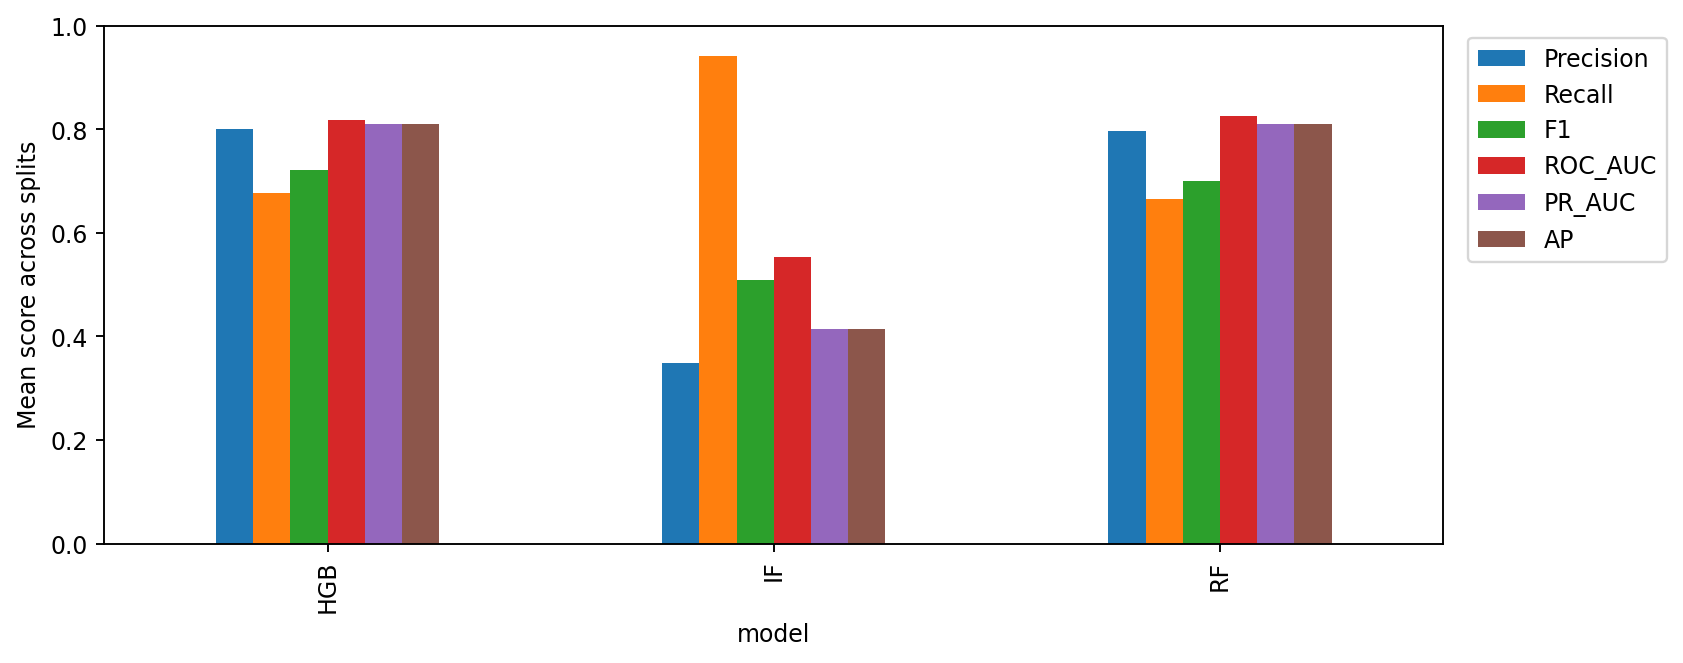

In [9]:
results = main(BASE_DIR, BASE_DIR / 'SKAB', seeds=(42, 43, 44))
from IPython.display import display, Markdown, Image
display(Markdown((BASE_DIR / 'results/results.md').read_text()))
display(Image(filename=str(BASE_DIR / 'img/final_comparison.png')))

## 저장 모델로 새 CSV 추론
첫 29개 관측은 warm-up입니다. 아래 예시는 기본적으로 주석 처리했습니다.

In [10]:
# predictions = predict_file(BASE_DIR / 'models/HGB_42.joblib', '/content/new_experiment.csv')
# display(predictions.head())
# predictions.to_csv(BASE_DIR / 'results/new_predictions.csv', index=False)

# SKAB 지도·비지도 이상탐지 실험

## 1. 목적과 첨부 자료와의 연결

기존 `abnormal detection_project.ipynb`의 데이터 로드·품질검사·시각화 이후 단계를 완성하는 별도 실행본이다. 첨부 강의자료 30쪽의 Point Adjustment 경고와 31쪽의 모델 2종 이상, 지표 3개 이상, 개선 실험, 라벨 사용 명시 조건을 반영했다. 기존 파일은 변경하지 않았다.

SKAB의 정식 명칭은 **Skoltech Anomaly Benchmark**이다. 일반 공장 전체를 장기간 관측한 데이터로 단정하면 안 된다. 물 순환 실험 장치의 센서에서 수집한 다변량 시계열이며 CSV마다 별도 실험이다. 공식 저장소의 현재 확보본은 정상 파일 1개와 이상 실험 34개, 총 35개이다. `valve1`은 펌프 유입부 밸브 조작, `valve2`는 유출부 밸브 조작이며 `other`는 다른 조건의 실험이다. 파일명이 같은 `1.csv`여도 서로 다른 실험이므로 반드시 상대 경로를 식별자로 사용한다.

사용 센서는 Accelerometer1RMS, Accelerometer2RMS, Current, Pressure, Temperature, Thermocouple, Voltage, **Volume Flow RateRMS**의 8개다. 마지막 센서명을 공백으로 분리하지 않는다. `anomaly`가 이진 분류 정답이며 `changepoint`는 변화점 표식이다. 두 라벨과 시간·파일명은 모델 입력에서 제외한다. 이 실험은 변화점 탐지 전용 평가가 아니라 매 관측 시점의 이상 여부 탐지다. 이상 구간의 집단적 변화와 센서 간 관계가 중요하므로 과거 윈도우 통계를 추가한다.

공식 원문: https://github.com/waico/SKAB 및 https://github.com/waico/SKAB/blob/master/data/README.md

## 2. 실행 방법과 자동 저장

가장 쉬운 방법은 `SKAB_experiment.ipynb`를 Colab에 업로드하고 위에서부터 실행하는 것이다. Drive 마운트 후 아래 경로를 자동 생성한다.

- 프로젝트: `/content/drive/MyDrive/CBNU/어프렌티스 프로젝트/SKAB_Project`
- 모든 그래프: 프로젝트의 `img/`
- 결과 표·예측·메타데이터: `results/`
- 학습 모델·전처리·임계값: `models/`
- 데이터 저장소: `SKAB/data/`

날짜별 실행 폴더로 바꾸려면 BASE_DIR만 바꿀 수 있다. 기본값으로 재실행하면 동일 파일명을 덮어쓴다. 데이터 폴더는 삭제하지 않으며 이미 존재하는 저장소는 자동 갱신하지 않는다. `run_metadata.json`에 실제 commit SHA와 각 CSV SHA256, Python 및 주요 패키지 버전을 기록한다. 정확한 재현에는 같은 코드·환경·commit을 사용한다. 새 저장소 clone은 그 실행 시점 HEAD이므로 과거 결과와 달라질 수 있다.

로컬 실행:

```bash
python -m pip install numpy pandas matplotlib scikit-learn joblib
python skab_pipeline.py --base ./SKAB_Project --repo ./SKAB --seeds 42 43 44
```

주요 초기화 코드는 다음과 같다.

```python
from pathlib import Path
BASE_DIR = Path('/content/drive/MyDrive/CBNU/어프렌티스 프로젝트/SKAB_Project')
IMG_DIR = BASE_DIR / 'img'
RESULT_DIR = BASE_DIR / 'results'
for p in [IMG_DIR, RESULT_DIR, BASE_DIR / 'models']:
    p.mkdir(parents=True, exist_ok=True)
```

## 3. 데이터 분할과 누수 방지

**행을 무작위로 섞거나 겹치는 윈도우를 만든 후 분할하지 않는다.** valve1·valve2·other 각각에서 CSV 파일을 섞어 약 60:20:20으로 배분한다. 정수 반올림 때문에 정확한 6:2:2는 아니다. 파일 내부 시간순서는 유지하며 하나의 CSV가 서로 다른 집합에 들어가지 않는다. 이 프로토콜은 같은 설비·같은 이상 유형 내의 새로운 실험에 대한 일반화 평가다. 미래 시간 전체에 대한 예측이나 보지 못한 고장 유형 검증과 동일하지 않다.

정상 파일은 시간순으로 60% train, 20% calibration, 20% holdout으로 분리하고 각 구간에서 윈도우와 forward-fill 상태를 새로 시작한다. 따라서 경계를 가로지르는 관측값 중복이 없다. 마지막 정상 holdout은 모델 선택에 쓰지 않고 최종 오탐률 점검에만 쓴다.

| 모델/단계 | 학습 데이터 | 학습 라벨 | 검증 라벨 |
|---|---|---|---|
| Random Forest | 학습 CSV 전체 + 정상 train | 사용 | AP로 후보 선택, F1으로 임계값 선택 |
| HistGradientBoosting | 위와 동일 | 사용 | 위와 동일 |
| Isolation Forest 기본 | 정상 train만 | 사용하지 않음 | 사용하지 않음; 정상 calibration 점수 99백분위 임계값 |
| Isolation Forest 개선 | 정상 train만 | 사용하지 않음 | **사용**; AP로 후보 선택, F1으로 임계값 선택 |

정상 파일이라는 사전 지식을 사용하는 IF는 정상 전용 학습(one-class/novelty 설정)이다. 모델 `.fit()`에 개별 이상 라벨을 주지는 않지만, 정상이라는 조건 자체도 감독 정보다. 개선 IF는 라벨 기반 검증을 결합하므로 전체 파이프라인을 완전 비지도라고 부르면 안 된다. 기본 IF만 검증 이상 라벨 없이 고정 설정으로 평가한다. 지도 모델에는 학습 CSV에 포함된 정상·이상과 정상 전용 train을 함께 주므로 학습 표본 수는 IF와 다르다. 표본 수가 같다는 조건의 비교가 아닌 각 방식의 현실적 데이터 사용 조건 비교다.

## 4. 전처리와 시계열 특징

1. 세미콜론 CSV를 읽고 숫자 변환 실패·무한대를 NaN으로 바꾼다. 센서 누락, 정답 라벨 오류, 잘못된 시각·중복 시각·비정렬 시각은 조용히 삭제하지 않고 오류를 낸다.
2. 시간 간격을 점검한다. 실제 데이터에 1초·2초 간격이 섞여 있다. 3배 초과 간격은 별도 구간으로 나눠 긴 공백을 넘는 윈도우와 보간을 막는다. 1~2초 지터는 유지하므로 **윈도우 30은 30개 관측값이지 정확히 30초가 아니다.** 엄밀한 시간 기반 윈도우가 필요하면 별도의 재표본화 실험으로 비교한다.
3. 같은 파일·연속 구간 내부에서 과거 방향 forward-fill을 사용한다. 선두 결측치는 해당 모델의 학습 자료에서 구한 센서 중앙값으로 채운다. 미래값을 쓰는 backfill과 양방향 보간은 하지 않는다. 이상치 제거·클리핑은 실제 이상 신호를 지울 수 있어 기본 적용하지 않는다.
4. 학습 자료에서만 중앙값과 StandardScaler를 적합한다. 검증·시험에는 transform만 수행한다. RF·HGB·IF는 트리 기반이어서 스케일링이 반드시 성능을 개선하는 것은 아니며, 여기서는 일관된 전처리와 확장성을 위한 것이다.
5. 기본 입력은 현재 시점 8개 센서다. 개선 입력은 최근 W개 관측의 현재값, 평균, 표준편차, 최솟값, 최댓값, 처음과 끝의 차이로 센서당 6개, 총 48개 특징이다. W=10,30, stride=1이다. 예측 정답은 **윈도우 마지막 시점의 anomaly**이며 창 안에 이상이 하나라도 있으면 1로 만드는 방식은 사용하지 않는다.
6. 모든 실험은 구간 첫 29개를 공통 제외해 같은 평가 시점을 사용한다. 파일과 split 경계를 넘는 창은 없다. 초기 warm-up 구간은 탐지 불가하며 본 점수에 포함되지 않는다. 실제 운용에서 이 초기 공백을 고려해야 한다.

## 5. 모델과 개선 실험

Random Forest는 비선형 센서 관계를 학습하는 지도학습 기준 모델이다. `class_weight='balanced'`를 사용한다. HistGradientBoosting은 잔차를 순차적으로 보완하는 부스팅 비교 모델이며 가중치를 `sample_weight`로 전달한다. HGB 내부 무작위 validation early stopping은 꺼서 외부 파일 분할과 혼동하지 않는다. Isolation Forest는 정상 특징 공간에서 쉽게 분리되는 표본에 높은 이상 점수를 준다. sklearn의 `score_samples`는 작은 값이 더 이상이므로 **부호를 뒤집어 높은 값=이상**으로 통일한다. 확률이라고 해석하지 않는다.

Autoencoder는 이번 최소 비교에 필수가 아니어서 포함하지 않았다. 이미 지도 2개·비지도 계열 1개가 요구 범위를 충족하며, 작은 데이터셋에서 복잡한 신경망을 추가하기 전에 누수 없는 기준 결과를 확보하는 설계다.

| 단계 | 변경 | 선택 기준 |
|---|---|---|
| baseline | 현재 8개 센서, 기본 파라미터 | 지도 임계값 0.5, IF 정상 calibration 99백분위 |
| threshold | 동일 점수에 임계값만 변경 | validation F1 최대; 동률이면 높은 임계값 |
| features | W=30 통계 특징 추가 | 동일 기본 파라미터, validation F1 임계값 |
| tuned | W=10/30, 기본/규제 파라미터 4개 후보 | validation AP 최대 후보, validation F1 임계값 |

RF 후보는 깊이 무제한/12, leaf 1/5, HGB는 learning rate .1/.05, leaf 31/15, L2 0/1의 미리 정한 묶음이다. IF는 max_samples 256/512, max_features 1/.75의 묶음이다. 이는 작은 사전 지정 후보 탐색이며 개별 파라미터의 인과 효과를 분리하는 완전 요인 실험은 아니다. 최종 tuned 후보는 rolling 특징 후보 중 선택한다. 따라서 항상 raw baseline보다 좋을 것이라는 보장은 없다.

시험 성능을 보고 후보나 임계값을 선택하지 않는다. 모든 단계를 미리 고정해 시험 결과에 나란히 보고하고 음수 개선량도 유지한다. 다만 동일 validation에서 AP 선택과 임계값 최적화를 하므로 검증 과적합은 남는다. 후보 수 확대 전에는 train/validation 안에서 파일 단위 nested CV 또는 독립 threshold-calibration 집합을 추가해야 한다. 시험 결과를 본 뒤 다시 튜닝한다면 새로운 최종 평가 집합을 마련한다.

## 6. 지표와 자동 생성 결과

- Precision = TP/(TP+FP): 발생한 경보 중 실제 이상 비율.
- Recall = TP/(TP+FN): 실제 이상 중 발견한 비율.
- F1: Precision과 Recall의 조화평균. 임계값에 의존한다.
- ROC-AUC: 연속 이상 점수의 순위 분리 능력. 불균형 데이터에서는 오탐 부담을 충분히 드러내지 못할 수 있다.
- PR-AUC: precision-recall 곡선의 사다리꼴 적분. 코드에서 `auc(recall, precision)`으로 계산한다.
- AP: `average_precision_score`. 계단식 recall 증가량으로 precision을 가중하는 별도 요약값이다. **PR-AUC와 AP를 같은 숫자로 표기하지 않는다.** 후보 선택은 AP를 사용한다.

라벨 0=정상, 1=이상이다. AUC는 이진 예측값이 아닌 연속 점수로 계산한다. 분모가 0인 precision/recall/F1은 0으로 처리하며 두 클래스가 없는 집합의 AUC는 NaN으로 둔다. 기본 표는 모든 시험 시점을 합친 point-wise 지표이므로 긴 파일의 기여가 크다. `per_file_*.csv`로 파일별 편차와 macro 평균도 확인한다.

`events_*.csv`에는 연속 이상 구간별 발견 여부와 발견된 구간의 첫 경보 지연을 저장한다. 미탐은 delay를 NaN으로 두므로 평균 지연만 보고 미탐이 없었다고 해석하면 안 된다. 이벤트 탐지율을 반드시 함께 본다. warm-up에서 이미 시작한 이벤트는 관측 가능한 첫 시점부터 지연을 계산하므로 이 보조 지표는 전체 원래 사건 시작 기준의 공식 벤치마크 점수가 아니다. 공식 range-based F1/VUS 점수를 구현한 것도 아니다.

**Point Adjustment는 전혀 적용하지 않는다.** 한 점을 맞혔다고 구간 전체를 정답 처리하지 않는다. 세 가지 split seed 42·43·44로 반복하고 평균 ± 표본 표준편차를 보고한다. 이는 파일 구성 및 모델 seed 변화에 대한 민감도이며 95% 신뢰구간이 아니다. 반복 시험 파일이 겹치므로 세 반복도 독립 표본이라고 볼 수 없다.

출력: `all_results.csv`, `results.md`, `final_summary.csv`, `improvement_deltas.csv`, `validation_history_*.csv`, `split_*.csv`, `predictions_*.csv`, `per_file_*.csv`, `events_*.csv`, `data_quality.csv`, `run_metadata.json`. 그래프는 분포, 최종 지표 비교, 단계별 F1, ROC/PR, 혼동행렬, 사전 지정 첫 시험 파일의 점수 시계열이다. 저장된 joblib에는 모델, 중앙값, scaler, 특징 설정, 임계값을 함께 넣어 `predict_file()`로 재사용한다. joblib은 신뢰할 수 있는 파일만 로드한다.

## 7. 결과 해석과 실무 고려사항

지도학습이 유리하면 이미 본 고장 유형의 센서 패턴을 정상/이상 라벨로 학습한 이점을 먼저 검토한다. 그것이 미관측 고장에도 우월하다는 근거는 아니다. IF가 낮으면 정상 학습 구간과 시험 운전 조건의 차이, 정상 상태의 다양성 부족, 여러 센서 관계 또는 지속 시간 정보를 충분히 표현하지 못한 가능성을 확인한다. 특히 정상 holdout의 FPR과 고장 실험 정상 구간의 FPR을 나누어 보면 운전 상태 변화와 고장 탐지를 구분하는 데 도움이 된다.

임계값만 바꿨을 때 F1이 바뀌어도 ROC-AUC·PR-AUC·AP는 같아야 한다. 이는 순위 모델의 개선이 아니라 의사결정 기준 개선이다. 특징·튜닝 후 AP와 F1이 함께 증가하면 분리 능력 개선 가능성이 있지만 파일별 편차와 반복 결과도 봐야 한다. rolling window는 노이즈를 줄이는 대신 급격한 변화에 반응이 늦어질 수 있고, 긴 창의 min/max는 과거 이상 영향이 남는다.

실무에서는 F1 최대만으로 경보 기준을 정하지 않는다. 미탐 비용이 크면 validation에서 최소 Recall 제약을 설정하고 그중 precision이 높은 임계값을 선택할 수 있다. 오탐 비용이 크면 정상 운전 시간당 경보 수를 제한한다. 본 코드의 FPR은 정상 관측 중 경보 비율이며, 시간당 독립 경보 이벤트 수와 다르다. 경보 병합·연속 K회 경보·cooldown을 적용하면 정책 자체를 validation에서 정하고 시험에서 탐지 지연 및 이벤트 미탐률을 다시 평가해야 한다.

실제 설치 전에는 파일/장비 단위 외부 검증, 특정 고장 유형 전체를 제외한 leave-one-type-out 검증, 계절·부하 변화와 센서 드리프트 점검이 필요하다. 이 실험의 같은 장치·작은 파일 수·동일 이상 유형 포함 결과를 다른 공장으로 바로 일반화할 수 없다. 라벨이 부족하면 정상 기준 모델로 시작해 운영자 확인 라벨을 축적하고 지도 모델로 확장하는 전략이 현실적이다.

## 참고 문서

- SKAB 공식: https://github.com/waico/SKAB
- Isolation Forest 점수 방향: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html
- AP 정의: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html



## 8. 이번 실제 실행 결과와 분석

공식 데이터 35개 CSV, 46,806행을 읽었고 센서 결측치는 0개였다. 결측 처리는 다른 입력에도 대비한 코드 경로다. 파일 분할은 각 seed에서 이상 실험 train 20개, validation 7개, test 7개이며 정상 train을 별도로 더했다. 예를 들어 seed 42의 시험 원시 행 수는 7,532행이며 warm-up 및 긴 간격 분리 이후의 평가 행 수는 예측 CSV에서 확인할 수 있다.

아래는 각 모델에서 validation으로 선택한 rolling 후보와 임계값의 시험 결과다. IF의 이 최종 결과에는 validation 라벨 사용이 포함된다.

| model | Precision | Recall | F1 | ROC_AUC | PR_AUC | AP |
| --- | --- | --- | --- | --- | --- | --- |
| HGB | 0.7948 ± 0.1214 | 0.6777 ± 0.1541 | 0.7173 ± 0.0663 | 0.8191 ± 0.0931 | 0.8113 ± 0.0795 | 0.8114 ± 0.0795 |
| IF | 0.3493 ± 0.0086 | 0.9421 ± 0.0916 | 0.5088 ± 0.0107 | 0.5539 ± 0.0443 | 0.4146 ± 0.0268 | 0.4149 ± 0.0267 |
| RF | 0.7852 ± 0.1587 | 0.6535 ± 0.2087 | 0.6838 ± 0.0867 | 0.8261 ± 0.1087 | 0.8111 ± 0.0857 | 0.8111 ± 0.0857 |

### 평균 F1의 단계별 변화

| model | baseline | threshold | features | tuned |
| --- | --- | --- | --- | --- |
| HGB | 0.6760 | 0.6687 | 0.6970 | 0.7173 |
| IF | 0.5000 | 0.5141 | 0.5100 | 0.5088 |
| RF | 0.6958 | 0.6735 | 0.6381 | 0.6838 |

- **HGB**: baseline 0.6760 → tuned 0.7173, +0.0413(4.13%p). 현재 조건에서 균형 잡힌 F1이 가장 높았다. 그러나 RF와 split별 편차가 겹치므로 통계적으로 확정적인 우열이라고 주장하지 않는다.
- **RF**: baseline 0.6958 → tuned 0.6838, −0.0120. AP는 0.7918 → 0.8111로 높아졌지만 F1은 낮아졌다. 점수 순위의 개선과 선택한 임계값의 일반화가 같은 문제가 아님을 보여 준다. 시험값을 보고 RF baseline을 사후 최종 모델로 교체하지 않았다.
- **IF**: baseline 0.5000 → tuned 0.5088, +0.0088. 최종 Recall 0.9421에 비해 Precision은 0.3493이다. 고장 실험 시험 자료의 정상 시점에 대한 평균 FPR은 **0.9560**이다. 거의 대부분의 정상 시점까지 이상으로 분류하므로 높은 Recall은 실용적 탐지의 증거가 아니다. 정상 파일 holdout FPR은 0.0412로 상대적으로 작아, 정상 전용 파일과 고장 실험 내 정상 구간의 분포 차이가 원인일 가능성이 있다. 원인 확정에는 센서별 분포와 운전조건 분석이 추가로 필요하다.
- IF의 모든 평가 이벤트가 즉시 탐지된 것처럼 보이는 보조 지표도 높은 상시 경보율과 함께 해석해야 한다. 무조건 경보하는 모델 역시 이벤트 recall과 첫 경보 지연이 좋게 나올 수 있다.
- 모든 모델에서 임계값 최적화가 시험 F1을 일관되게 높이지는 않았다. 검증 점수만 보고 성능 개선 성공을 선언하면 안 된다.

이 결과는 같은 유형이 학습과 시험에 모두 존재하는 파일 분리 프로토콜의 결과다. **지도학습이 모든 환경에서 우월하다**, **비지도학습은 사용할 수 없다**라는 결론으로 확대하지 않는다. IF의 정상 데이터 다양성 확보를 다음 실험으로 권한다. 학습 CSV에서 라벨=0인 구간을 추가하는 방법은 가능하지만, 정상 구간 선별에 라벨을 사용하므로 감독 정보가 늘어났음을 별도로 표시하고 정상 구간 경계를 넘는 창을 만들지 않아야 한다.

### 검증한 항목

실제 데이터로 세 seed의 45개 후보 모델 학습과 36개 단계별 시험 평가를 수행했다. 미래 관측값 변경이 이전 특징에 영향을 주지 않는지, 라벨을 바꿔도 입력 특징이 같은지, W=10/30의 평가 시점이 같은지, 임계값 인덱스가 맞는지 확인했다. 저장 모델 재로딩 추론과 시험 예측의 일치도 확인했다. 그래프는 실제 결과로 생성했다. 이번 실행 환경과 데이터 commit은 `results/run_metadata.json`에 기록했다.
